# South African Real Estate Market Analysis 

This project demonstrates an end-to-end ETL (Extract, Transform, Load) and Exploratory Data Analysis (EDA) workflow using a South African residential property datasets. The objective is to transform raw property listing data into an analysis-ready dataset and uncover insights regarding property pricing, market activity, surburb performance, and agent effectiveness. 

The project combines transaction-level data with property agent information and suburb-level demographic indicators to provide a more comprehensive view of the South African property market. 

## 1. Import Libraries 

In [1]:
import pandas as pd 
import numpy as np 

import matplotlib.pyplot as plt 
import seaborn as sns 

pd.set_option('display.max_columns', None)

sns.set_style("whitegrid")

## 2. Load Datasets

In [2]:
listings = pd.read_csv("listings_raw.csv")
agents = pd.read_csv("agents_dim.csv")
suburbs = pd.read_csv("suburbs_dim.csv")

print("Listings Shape:", listings.shape)
print("Agents Shape:", agents.shape)
print("Suburbs Shape:", suburbs.shape)

Listings Shape: (6120, 17)
Agents Shape: (40, 4)
Suburbs Shape: (20, 5)


## 3. Inspect Dataset Structure 

In [3]:
listings.head()

,listing_id,listing_date,suburb,property_type,bedrooms,bathrooms,garages,floor_area_m2,erf_size_m2,year_built,has_pool,security_estate,asking_price_zar,sold_price_zar,days_on_market,status,agent_id
0,RE003728,2025-07-06,Constantia,Apartment,1.0,1,0.0,55.0,0,2005.0,1,0,R 2 035 000,1688000.0,180.0,Sold,AG040
1,RE004505,20/08/2025,Bellville,APARTMENT,3.0,2,0.0,126.0,0,2014.0,0,0,1630000,1552000.0,85.0,Sold,AG005
2,RE000018,2023-06-03,Hatfield,Apartment,3.0,2,2.0,119.0,0,1974.0,0,1,R 1 395 000,1425000.0,34.0,Sold,NaN
3,RE000874,26 Dec 2023,Umhlanga,Townhouse,4.0,4,3.0,238.0,257,NaN,0,1,7535000,6783000.0,55.0,Sold,AG013
4,RE004915,29/04/2025,Centurion,Apartment,3.0,2,1.0,104.0,0,1960.0,1,0,2140000,1914000.0,26.0,Sold,NaN


In [4]:
listings.info() 

<class 'pandas.DataFrame'>
RangeIndex: 6120 entries, 0 to 6119
Data columns (total 17 columns):
 #   Column            Non-Null Count  Dtype  
---  ------            --------------  -----  
 0   listing_id        6120 non-null   str    
 1   listing_date      6120 non-null   str    
 2   suburb            6120 non-null   str    
 3   property_type     6120 non-null   str    
 4   bedrooms          5937 non-null   float64
 5   bathrooms         6120 non-null   int64  
 6   garages           5875 non-null   float64
 7   floor_area_m2     5814 non-null   float64
 8   erf_size_m2       6120 non-null   int64  
 9   year_built        5442 non-null   float64
 10  has_pool          6120 non-null   int64  
 11  security_estate   6120 non-null   int64  
 12  asking_price_zar  6120 non-null   str    
 13  sold_price_zar    4455 non-null   float64
 14  days_on_market    5998 non-null   float64
 15  status            6120 non-null   str    
 16  agent_id          5998 non-null   str    
dtypes: flo

In [5]:
listings.describe()

,bedrooms,bathrooms,garages,floor_area_m2,erf_size_m2,year_built,has_pool,security_estate,sold_price_zar,days_on_market
count,5937.000000,6120.000000,5875.000000,5814.000000,6120.000000,5442.000000,6120.000000,6120.000000,4.455000e+03,5998.000000
mean,2.672730,2.190359,1.488681,156.847781,491.668791,1990.370452,0.288562,0.335621,3.543297e+06,57.623374
std,1.238227,1.087392,0.844377,297.964736,522.458712,20.318947,0.453131,0.472246,2.584946e+06,42.589368
min,0.000000,0.000000,0.000000,0.000000,0.000000,1955.000000,0.000000,0.000000,2.720000e+05,-5.000000
25%,2.000000,1.000000,1.000000,80.000000,0.000000,1973.000000,0.000000,0.000000,1.568000e+06,27.000000
50%,3.000000,2.000000,2.000000,165.000000,336.000000,1990.000000,0.000000,0.000000,2.953000e+06,48.000000
75%,4.000000,3.000000,2.000000,207.000000,800.000000,2008.000000,1.000000,1.000000,4.818500e+06,77.000000
max,5.000000,5.000000,3.000000,9999.000000,2477.000000,2031.000000,1.000000,1.000000,2.237100e+07,351.000000


## 4. Data Cleaning 

### 4.1 Missing Values Analysis 

In [6]:
listings.isnull().sum().sort_values(ascending=False)

sold_price_zar      1665
year_built           678
floor_area_m2        306
garages              245
bedrooms             183
agent_id             122
days_on_market       122
listing_id             0
listing_date           0
erf_size_m2            0
bathrooms              0
suburb                 0
property_type          0
asking_price_zar       0
security_estate        0
has_pool               0
status                 0
dtype: int64

### 4.2 Duplicate Records 

In [7]:
listings.duplicated().sum()

np.int64(90)

### 4.3 Standardize Text Fields 

In [8]:
listings['property_type'] = (
    listings['property_type']
    .str.strip()
    .str.title()
)

listings['suburb'] = (
    listings['suburb']
    .str.strip()
    .str.title()
)

### 4.4 Clean Currency Fields 

In [9]:
price_cols = [
    'asking_price_zar',
    'sold_price_zar'
]

for col in price_cols:

    listings[col] = (
        listings[col]
        .astype(str)
        .str.replace('R', '', regex=False)
        .str.replace(',', '', regex=False)
        .str.replace(' ', '', regex=False)
    )

    listings[col] = pd.to_numeric(
        listings[col],
        errors='coerce'
    )   

### 4.4 Convert Dates 

In [10]:
listings['listing_date'] = pd.to_datetime(
    listings['listing_date'],
    errors='coerce'
)

## 5. Data Integration

In [11]:
df = listings.merge(
    agents, 
    on='agent_id',
    how='left'
) 

df = df.merge(
    suburbs, 
    on='suburb',
    how='left'
)

## 5. Feature Engineering 

### 5.1 Property Age 

In [13]:
df['property_age']= 2026 - df['year_built']

### 5.2 Price Per Square Meter 

In [14]:
df['price_per_m2'] = (
    df['sold_price_zar'] / 
    df['floor_area_m2']
) 

### 5.3 Total Rooms 

In [15]:
df['total_rooms'] = (
    df['bedrooms'] +
    df['bathrooms'] 
) 

### 5.4 Discount Percentage 

In [16]:
df['discount_pct'] = (
    (df['asking_price_zar']
     - df['sold_price_zar'])
    / df['asking_price_zar']
) * 100

## 6. Exploratory Data Analysis 

### 6.1 Property Type Distribution 

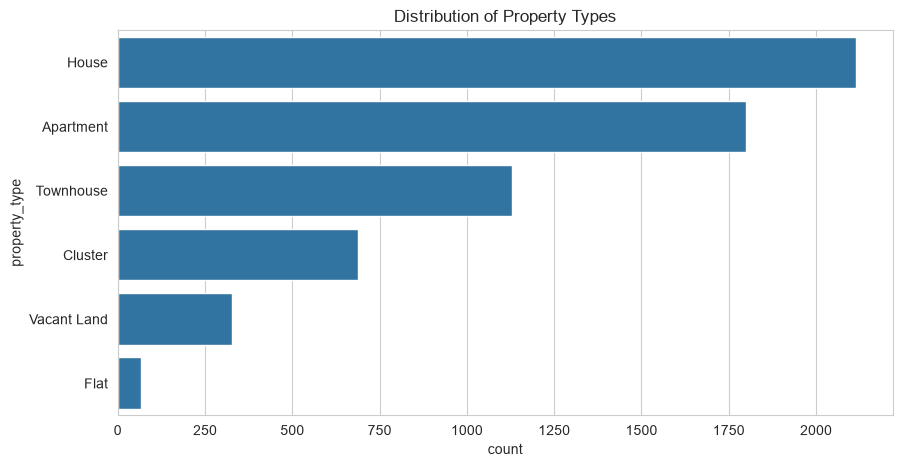

In [17]:
plt.figure(figsize=(10,5))

sns.countplot(
    data=df,
    y='property_type',
    order=df['property_type']
    .value_counts()
    .index
)

plt.title("Distribution of Property Types")
plt.show()

**Houses** represent the largest share of listings in the dataset **(2,125 properties)**, indicating that detached residential homes dominate the sample property market. **Apartments** form the second-largest segment, followed by **townhouses. Clusters, vacant land, and flats** account for a much smaller proportion of listings, suggesting that these property types occupy niche segments of the market.

### 6.2 Top 10 Suburbs by Number of Listings

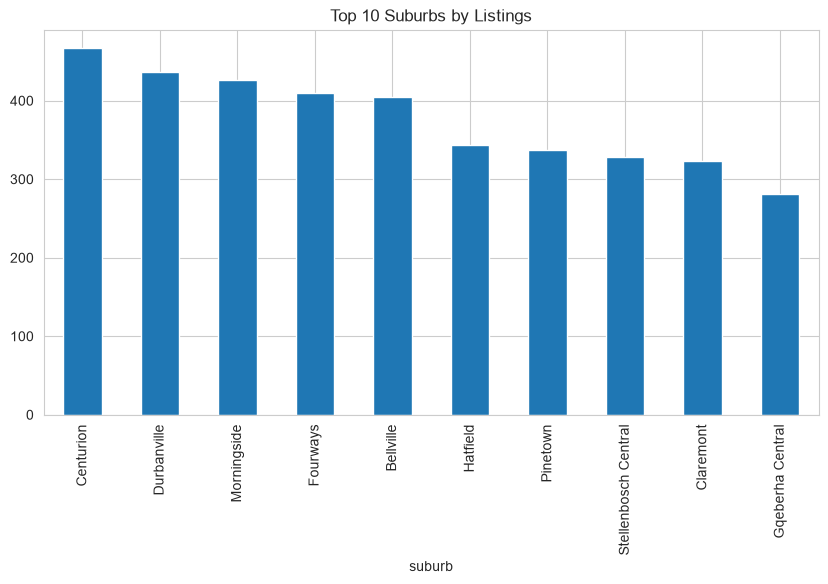

In [19]:
top_suburbs = (
    df['suburb']
    .value_counts()
    .head(10)
)

top_suburbs.plot(
    kind='bar', 
    figsize=(10,5)
)
plt.title("Top 10 Suburbs by Listings")
plt.show()

**Centurion** recorded the highest number of property listings, followed by **Durbanville, Morningside, Fourways**, and **Bellville.** The high concetration of listings in these suburbs may indicate stronger market activity, higher housing demand, or greater property development compared to other locations. **Gqeberha Central** recorded the fewest listings among the top ten suburbs.

### 6.3 Distribution of Property Prices 

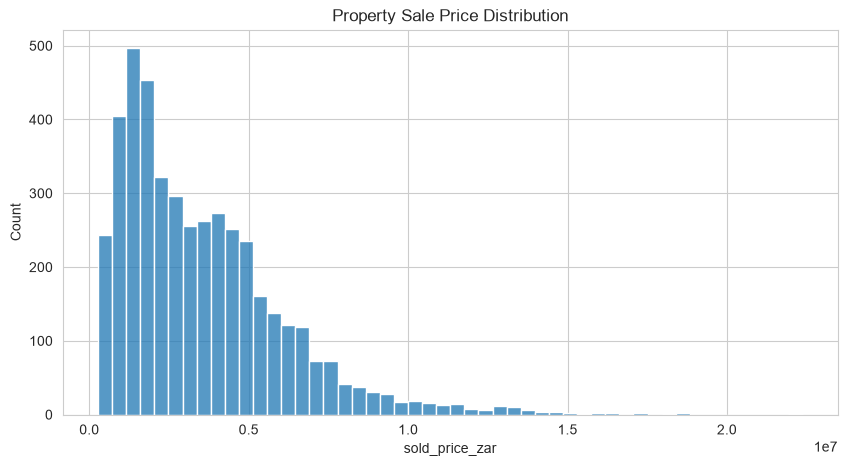

In [21]:
plt.figure(figsize=(10,5))

sns.histplot(
    df['sold_price_zar'],
    bins=50
)

plt.title("Property Sale Price Distribution")
plt.show()

The sale price distribution is positively skewed, with most properties concetrated in the lower-to-mid price range and a relatively small number of high-value properties creating a long right tail. This indicates that luxury properties are present in the market by represent only a small propotion of total listings. 

### 6.4 Size vs Selling Price 

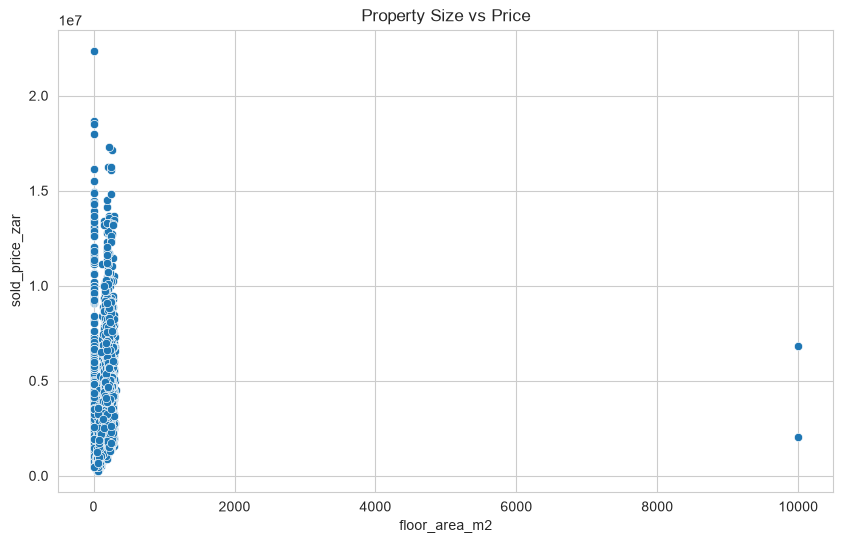

In [23]:
plt.figure(figsize=(10,6))

sns.scatterplot(
    data=df,
    x='floor_area_m2',
    y='sold_price_zar'
)

plt.title("Property Size vs Price")
plt.show()

The scatter plot (Property size vs price) shows a positive relationship between floor area and selling price; however, the visualization is heavily influenced by a small number of extreme floor-area outliers. Most properties are clustered within a much smaller size range, while two properties with floor areas close to 10,000 m2. 

### 6.5 Crime Index vs Selling Price 

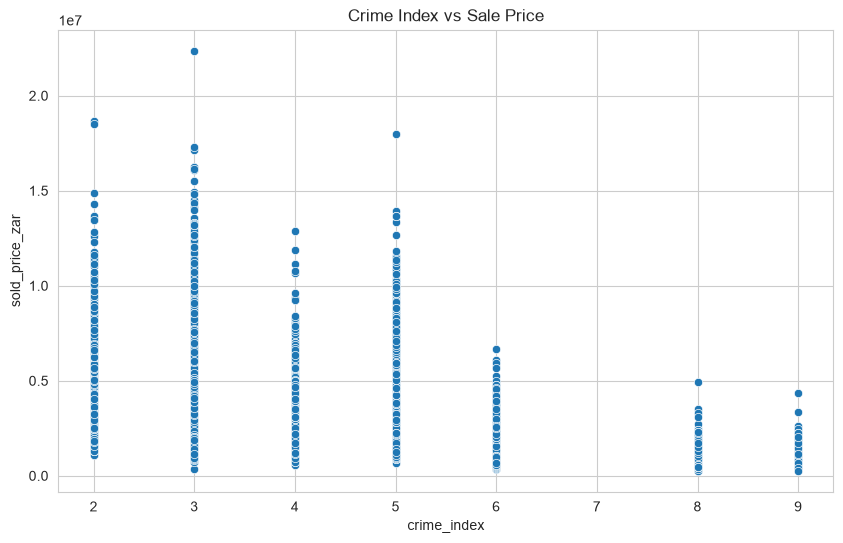

In [25]:
plt.figure(figsize=(10,6))

sns.scatterplot(
    data=df,
    x='crime_index',
    y='sold_price_zar'
)

plt.title("Crime Index vs Sale Price")
plt.show()

The scatter plot (Crime index vs Selling Price) shows that the properties located in suburbs with lower crime indices generally achieve higher selling prices **(Properties from crime index 2 to 5)**. This suggests that perceived safety is an important driver of residential property demand and valuation. The properties from **crime index 6 to 9 sold** at a lesser prices as there is high crime rate in this locations. 

### 6.6 Correlation Matrix 

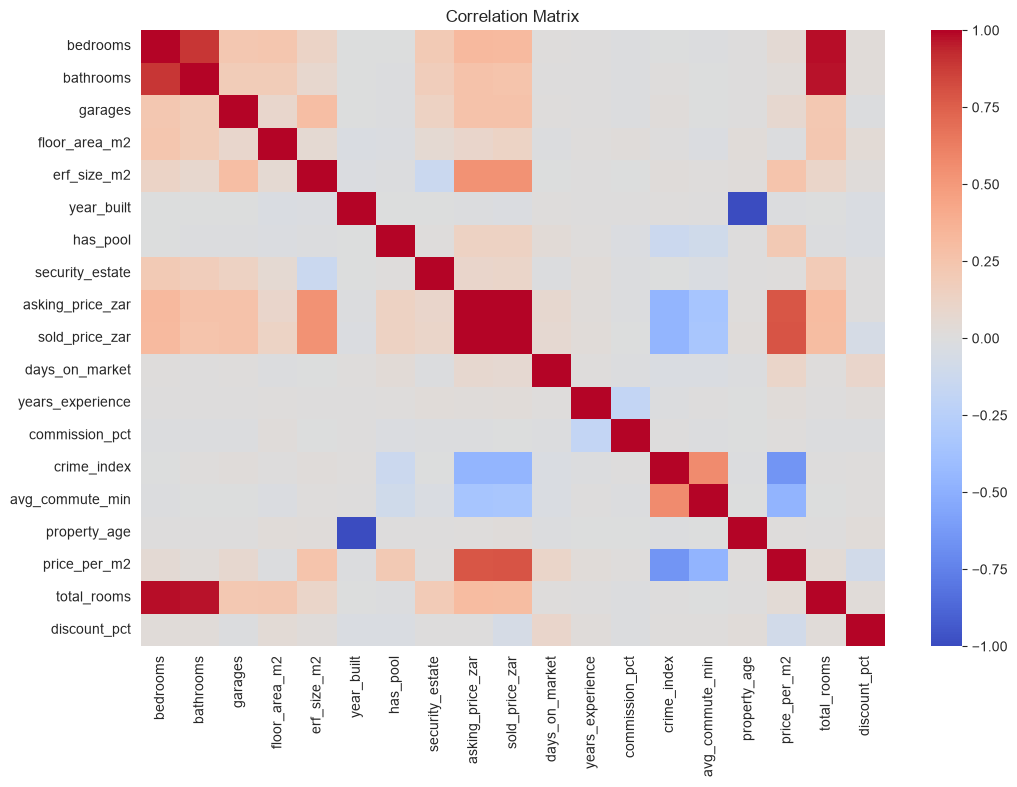

In [26]:
numeric_df = df.select_dtypes(
    include='number'
)

plt.figure(figsize=(12,8))

sns.heatmap(
    numeric_df.corr(), 
    cmap='coolwarm', 
    annot=False
)

plt.title("Correlation Matrix")
plt.show()

The correlation analysis reveals several expected relationships within the property market. **Bedrooms and bathrooms** show a strong positive correlation (r= 0.75), indicating that larger homes generally include more bathroom facilities. **Total rooms** exhibits near-perfect correlations with both **bedrooms and bathrooms** because it is an engineered feature derived from these variables. **Property age and year built** display a strong negative correlation (r=-0.95), as newer properties naturally have lower ages. 

## 7. Conclusion 

The exploratory data analysis provided valuable insights into the South African residential property market. Houses were found to be the most common property type, followed by apartments and townhouses, indicating that detached residential homes dominate the market. Listing activity was concentrated in suburbs such as **Centurion, Durbanville, and Morningside,** suggesting higher levels of market activity and housing demand in these areas. 

The sale price distribution exhibited a positive skew, with most properties falling within the lower-to-mid price range and a small number of luxury properties contributing to a long right tail. Analysis of property size and selling price revealed a generally positive relationship, indicating that larger properties tend to command higher market values. However, a small number of extreme outliers influenced the overall distribution and visualization. 

Suburb-level analysis showed that properties located in areas with lower crime indices generally achieved higher selling prices, suggesting that neighbourhood safety may play an important role in property valuation. Correlation analysis further revealed strong relationdhips between bedrooms and bathrooms, while engineered features such as total rooms and property age exhibited expected correlations with their source variables. 

Overall, the findings suggest that property value is influenced by a combination of factors including property size, location, property characteristics, and neighbourhood conditions. The ETL process successfully transformed raw data into an analysis-ready dataset, enabling meaningful business insights and demonstraning practical skills in data cleaning, feature engineering, data integration, and exploratory data analysis. 
